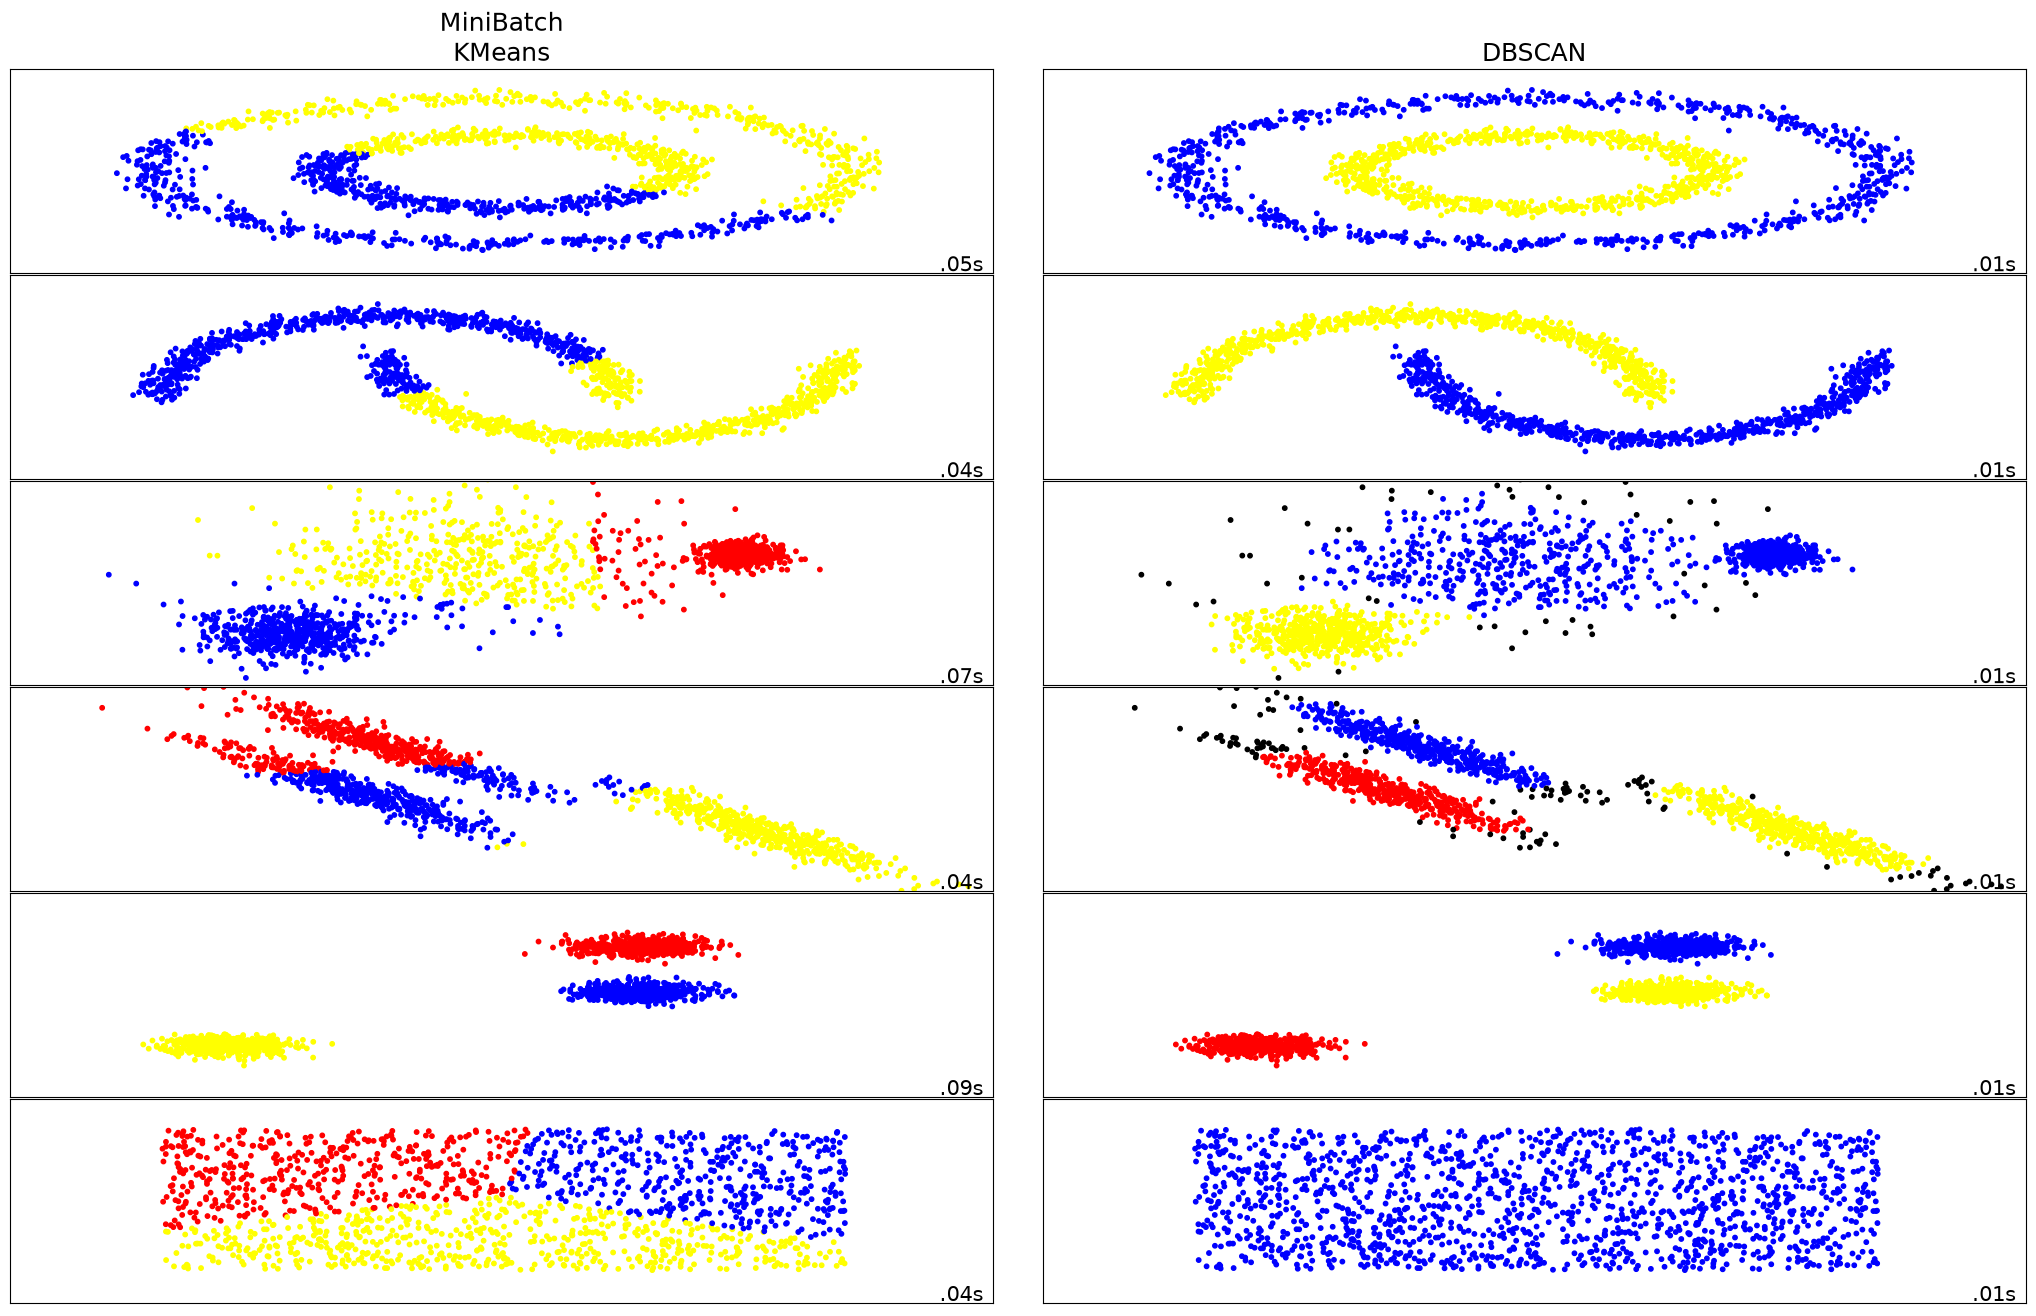

In [14]:
import time
import warnings
from itertools import cycle, islice
import matplotlib.pyplot as plt
import numpy as np
from sklearn import cluster, datasets
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler

np.random.seed(0)

# ============
# Generate datasets
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(9 * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets_list = [
    (noisy_circles, {"damping": 0.77, "preference": -240, "quantile": 0.2, "n_clusters": 2, "min_samples": 20, "xi": 0.25}),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (varied, {"eps": 0.18, "n_neighbors": 2, "min_samples": 5, "xi": 0.035, "min_cluster_size": 0.2}),
    (aniso, {"eps": 0.15, "n_neighbors": 2, "min_samples": 20, "xi": 0.1, "min_cluster_size": 0.2}),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets_list): # перебор 6 датасетов
    # деф параметры для фигур  
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset # ТОЧКИ и ответы

    # нормализаци данных   чтобы сред знач было раавно 0 и алгоритмы не путались в масштабаз
    X = StandardScaler().fit_transform(X)

    # создание моделей. Инициализируем алгоритмы ЗДЕСЬ, чтобы они получали актуальные params на каждом шаге цикла!
    two_means = cluster.MiniBatchKMeans(
        n_clusters=params["n_clusters"],  # параметр для кмеанс
        random_state=42, 
        n_init="auto"
    )
    dbscan = cluster.DBSCAN(
        eps=params["eps"], # радиус поиска соседей
        min_samples=params["min_samples"] # сколько точекдолжно оказаться внутри радиуса
    )

    clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )
    # обучение моделей
    for name, algorithm in clustering_algorithms:
        t0 = time.time()

        # Обучаем модель
        with warnings.catch_warnings():
            warnings.simplefilter("ignore") # скрываем предупрежд
            algorithm.fit(X) # обучение

        t1 = time.time() 
        
        if hasattr(algorithm, "labels_"): # есть ли атрибут для сохраненя результата
            y_pred = algorithm.labels_.astype(int)
        else:
            y_pred = algorithm.predict(X)

        # Отрисовка подграфика
        plt.subplot(len(datasets_list), len(clustering_algorithms), plot_num) # (колво строк, столбцо, поряд номер графикак)
        if i_dataset == 0: # первый датасет
            plt.title(name, size=18)

        # Цвета для кластеров (-1 в DBSCAN — шум, красим его в черный)
        colors = np.array(list(islice(cycle(["blue", "yellow", "red"]), int(max(y_pred) + 1))))
        colors = np.append(colors, ["black"])
        
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[y_pred]) # отрисовка тоек по цветам
        # фиксация осей координат по х и у
        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        # скрытие осей и координат
        plt.xticks(())
        plt.yticks(())
        
        # Добавляем время в угол
        plt.text(0.99, 0.01, ("%.2fs" % (t1 - t0)).lstrip("0"), transform=plt.gca().transAxes, size=15, horizontalalignment="right")
        plot_num += 1

